Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
📦 Creating a sample Indian Traffic COCO dataset for exploration...
✅ Created dataset with 15 images and 51 boxes.

📊 Generating exploration graphs...


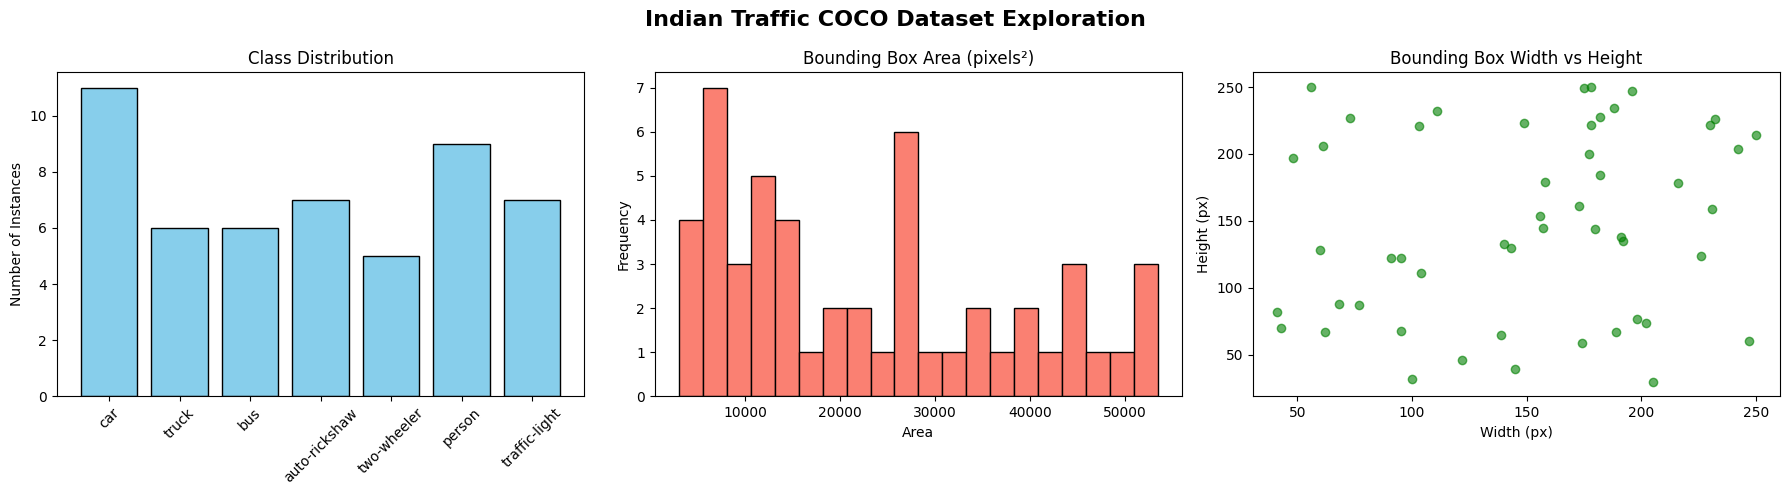


🖼️ UPLOAD AN IMAGE FOR LIVE DETECTION


Saving img.jpeg to img.jpeg
✅ Loaded: img.jpeg
🤖 Loading YOLOv8 model...
🔍 Detecting objects...

0: 448x640 6 persons, 16 cars, 1 bus, 2 trucks, 391.1ms
Speed: 35.8ms preprocess, 391.1ms inference, 37.5ms postprocess per image at shape (1, 3, 448, 640)


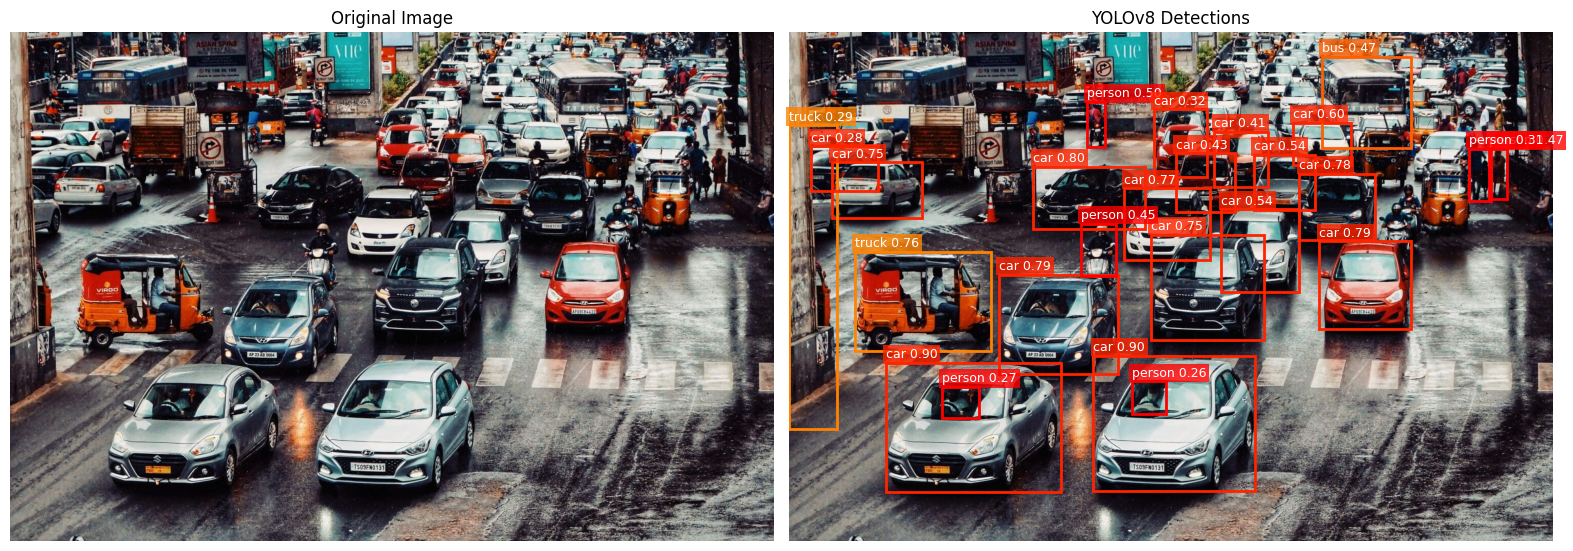


✅ Detected 25 objects!

--- Detection Summary ---
  • car             (Confidence: 0.90)
  • car             (Confidence: 0.90)
  • car             (Confidence: 0.80)
  • car             (Confidence: 0.79)
  • car             (Confidence: 0.79)
  • car             (Confidence: 0.78)
  • car             (Confidence: 0.77)
  • truck           (Confidence: 0.76)
  • car             (Confidence: 0.75)
  • car             (Confidence: 0.75)
  • car             (Confidence: 0.60)
  • car             (Confidence: 0.54)
  • car             (Confidence: 0.54)
  • person          (Confidence: 0.50)
  • bus             (Confidence: 0.47)
  • person          (Confidence: 0.47)
  • person          (Confidence: 0.45)
  • car             (Confidence: 0.43)
  • car             (Confidence: 0.41)
  • car             (Confidence: 0.32)
  • person          (Confidence: 0.31)
  • truck           (Confidence: 0.29)
  • car             (Confidence: 0.28)
  • person          (Confidence: 0.27)
  • person   

In [1]:
# ============================================================
# 🇮🇳 COCO Dataset Exploration: Indian Traffic Images
# ============================================================

import os, json, random, io, requests
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from google.colab import files

# 1. Install YOLOv8
!pip install -q ultralytics
from ultralytics import YOLO

# ============================================================
# 2. CREATE A SYNTHETIC COCO-STYLE DATASET (Indian Traffic)
# ============================================================
# (Replace this block with loading the real UVH-26 or Kaggle dataset JSON)
print("📦 Creating a sample Indian Traffic COCO dataset for exploration...")

os.makedirs("sample_traffic/images", exist_ok=True)

# Define classes commonly found in Indian traffic datasets[reference:2]
classes = ["car", "truck", "bus", "auto-rickshaw", "two-wheeler", "person", "traffic-light"]
class_to_id = {name: i+1 for i, name in enumerate(classes)}

# Create a COCO-format annotations dictionary
coco_data = {
    "info": {"description": "Synthetic Indian Traffic Dataset", "version": "1.0"},
    "categories": [{"id": cid, "name": name, "supercategory": "vehicle"} for name, cid in class_to_id.items()],
    "images": [],
    "annotations": []
}

# Generate 15 fake images with bounding boxes
ann_id = 1
for img_id in range(1, 16):
    # Create a random image (gray background with some noise)
    img = np.random.randint(0, 255, (640, 640, 3), dtype=np.uint8)
    img_path = f"sample_traffic/images/img_{img_id:03d}.jpg"
    Image.fromarray(img).save(img_path)

    coco_data["images"].append({
        "id": img_id,
        "file_name": f"img_{img_id:03d}.jpg",
        "width": 640, "height": 640
    })

    # Add 2-5 random bounding boxes per image
    for _ in range(random.randint(2, 5)):
        cat = random.choice(list(class_to_id.values()))
        w = random.randint(30, 250)
        h = random.randint(30, 250)
        x = random.randint(0, 640 - w)
        y = random.randint(0, 640 - h)

        coco_data["annotations"].append({
            "id": ann_id,
            "image_id": img_id,
            "category_id": cat,
            "bbox": [x, y, w, h],
            "area": w * h,
            "iscrowd": 0
        })
        ann_id += 1

# Save the JSON
with open("sample_traffic/annotations.json", "w") as f:
    json.dump(coco_data, f, indent=2)
print(f"✅ Created dataset with {len(coco_data['images'])} images and {len(coco_data['annotations'])} boxes.")

# ============================================================
# 3. EXPLORE & VISUALIZE (Graphs)
# ============================================================
print("\n📊 Generating exploration graphs...")

# Extract data from COCO JSON
cat_id_to_name = {c["id"]: c["name"] for c in coco_data["categories"]}
cat_counts = {name: 0 for name in cat_id_to_name.values()}
areas, widths, heights = [], [], []

for ann in coco_data["annotations"]:
    cat_name = cat_id_to_name[ann["category_id"]]
    cat_counts[cat_name] += 1
    areas.append(ann["area"])
    widths.append(ann["bbox"][2])
    heights.append(ann["bbox"][3])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Indian Traffic COCO Dataset Exploration", fontsize=16, fontweight='bold')

# Graph 1: Class Distribution
axes[0].bar(cat_counts.keys(), cat_counts.values(), color='skyblue', edgecolor='black')
axes[0].set_title("Class Distribution")
axes[0].set_ylabel("Number of Instances")
axes[0].tick_params(axis='x', rotation=45)

# Graph 2: Bounding Box Area Histogram
axes[1].hist(areas, bins=20, color='salmon', edgecolor='black')
axes[1].set_title("Bounding Box Area (pixels²)")
axes[1].set_xlabel("Area")
axes[1].set_ylabel("Frequency")

# Graph 3: Width vs Height Scatter
axes[2].scatter(widths, heights, alpha=0.6, color='green')
axes[2].set_title("Bounding Box Width vs Height")
axes[2].set_xlabel("Width (px)")
axes[2].set_ylabel("Height (px)")

plt.tight_layout()
plt.show()

# ============================================================
# 4. LIVE INFERENCE: UPLOAD AN IMAGE & DETECT
# ============================================================
print("\n" + "="*60)
print("🖼️ UPLOAD AN IMAGE FOR LIVE DETECTION")
print("="*60)
uploaded = files.upload()

if not uploaded:
    print("❌ No image uploaded. Skipping inference.")
else:
    filename = list(uploaded.keys())[0]
    img_bytes = uploaded[filename]
    img = Image.open(io.BytesIO(img_bytes)).convert("RGB")
    img_np = np.array(img)

    print(f"✅ Loaded: {filename}")

    # Load YOLOv8 Nano (pre-trained on COCO)
    print("🤖 Loading YOLOv8 model...")
    model = YOLO('yolov8n.pt')

    # Run inference
    print("🔍 Detecting objects...")
    results = model(img_np)

    # Extract results
    boxes = results[0].boxes
    if len(boxes) == 0:
        print("⚠️ No objects detected. Try a clearer image.")
        plt.figure(figsize=(8, 8))
        plt.imshow(img)
        plt.title("No Detections")
        plt.axis("off")
        plt.show()
    else:
        # Prepare visualization
        fig, ax = plt.subplots(1, 2, figsize=(16, 6))

        # Left: Original Image
        ax[0].imshow(img)
        ax[0].set_title("Original Image")
        ax[0].axis("off")

        # Right: Image with Bounding Boxes
        ax[1].imshow(img)
        ax[1].set_title("YOLOv8 Detections")
        ax[1].axis("off")

        # Draw boxes
        colors = plt.cm.hsv(np.linspace(0, 1, len(model.names))).tolist()
        for box in boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
            conf = box.conf[0].cpu().item()
            cls = int(box.cls[0].cpu().item())
            label = f"{model.names[cls]} {conf:.2f}"

            # Draw rectangle
            rect = patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                     linewidth=2, edgecolor=colors[cls], facecolor='none')
            ax[1].add_patch(rect)
            # Add label
            ax[1].text(x1, y1-10, label, color='white', fontsize=9,
                       bbox=dict(facecolor=colors[cls], alpha=0.8, edgecolor='none', pad=2))

        plt.tight_layout()
        plt.show()

        print(f"\n✅ Detected {len(boxes)} objects!")
        # Print a summary table
        print("\n--- Detection Summary ---")
        for box in boxes:
            cls = int(box.cls[0].cpu().item())
            conf = box.conf[0].cpu().item()
            print(f"  • {model.names[cls]:<15} (Confidence: {conf:.2f})")